# Pilot Study: Sizing the Connectome-Degradation Sweep (Study 2a: region x repetition)

Sizes `wCSET` vs `CSET` across 6 connectome-degradation severity levels, **given one
representative corrupted connectome per severity level** -- the connectome-*draw-count*
question (how many independently-corrupted connectomes are needed at a given severity)
is handled separately in `pilot_degradation_draws_power_analysis.ipynb`, not here. These
are two independent pilots rather than one joint model: they assume region-variability
and connectome-draw-variability are independent/additive, traded for reusing the
existing 2-way `simulate_splitplot_power` machinery unchanged in both, instead of
building a new 3-way one that jointly models both random-effects layers at once. The
real study's `(k regions, r repetitions, c draws)` design should take the more
conservative of this pilot's `(k, r)` recommendation and the draw pilot's own.

**No new simulation needed** -- degradation severity only changes which connectome
`wCSET`/`CSET` use as their harmonic-prior source at reconstruction time, not what
ground truth gets simulated. Reuses `sub-simf10-pilot`'s existing 208 runs directly
(same dataset as the original 6-method pilot and the surrogate-comparison pilot).

**Corruption method**: `brutal` (`perturb_connectome_topology`, uniform random edge
deletions/additions, exact closed-form severity) -- not `dmri` (unresolved
non-monotonic performance anomaly at high severity, see memory
`sabotage-connectome-study`) or `swap` (needs empirical calibration, unnecessary
overhead here). Same recipe as `sabotage_connectome.ipynb`'s `corrupt("brutal", ...)`.

**Severity levels**: `[0, 20, 40, 60, 80, 100]`, matching both your spec (6 levels) and
`sabotage_connectome.ipynb`'s own grid exactly.

**Design**: fit **separately per severity level** (`fixed_col="method"`, `m=2`,
`group_col="region"`) rather than a joint `method x percentage x region` model -- same
reasoning as the noise-sweep pilot: a full random-slope covariance was already singular
at the original pilot's scale, and stacking another factor on top only makes that worse.

**Companion script** (only the solve step -- no generation step needed):
- `pilot_degradation_02_solve.py` -- brutal-corrupts one connectome per severity,
  caches eigenspectra, solves all 208 existing runs under all 12 conditions

## 🧬 - Running the pilot (run separately first)

`pilot_degradation_02_solve.py` verifies data integrity (known `con`/`eig`/`Simulator`
staleness trap), brutal-corrupts the connectome once at each non-zero severity level
(`percentage=0` reuses the clean `eig` directly), caches the 5 resulting eigenspectra via
`cache_cst_batch`, then solves all 208 existing `sub-simf10-pilot` runs under
`wCSET`/`CSET` x all 6 severities -- same `build_phase_data_hrp_pp_curve`/
`score_source_reconstruction` scoring as the other pilots, with each checkpoint row
tagged `method`/`percentage` as separate columns. Checkpointed per run
(`pilot_degradation_metrics/run-{run:03d}.json` + `_curves.npz`), same crash-recovery
behavior as the other pilots' solve scripts.

Run it before executing the cells below.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

import mindmap as mm

dm = mm.io.TutoManager("../../config.yml")
sub_pilot = "simf10-pilot"

METRICS_DIR = Path("pilot_degradation_metrics")
OUTCOMES = ["localization_error_hrp", "ap_hrp", "ap_pp", "correlation_auc"]
METHODS = ["wcset", "cset"]
PERCENTAGES = [0, 20, 40, 60, 80, 100]
M = len(METHODS)

## 📊 - Aggregate outcome measures

Same three outcome measures per `(region, repetition, percentage, method)` as the
other pilots. `method`/`percentage` are already columns in each checkpoint row
(tagged by `pilot_degradation_02_solve.py`), so `load_pilot_checkpoints` only needs to
pull `region`/`repetition` from the run index.

In [2]:
df_index = pd.read_csv(dm.roots["sim"] / f"sub-{sub_pilot}" / "simulation_index.tsv", sep="\t")

df = mm.analysis.power.load_pilot_checkpoints(df_index, METRICS_DIR, index_cols=("region", "repetition"))
print(f"Aggregated {len(df)} (region,repetition,percentage,method) rows "
      f"({df['run'].nunique()} runs x {df['method'].nunique()} methods x {df['percentage'].nunique()} severities).")
df.to_csv("pilot_degradation_outcomes.tsv", sep="\t", index=False)
df.head()

Aggregated 2496 (region,repetition,percentage,method) rows (208 runs x 2 methods x 6 severities).


,run,method,percentage,localization_error_hrp,ap_hrp,ap_pp,correlation_auc,region,repetition
0,1,wcset,0,0.000000,0.540026,0.930348,0.299989,ctx-rh-posteriorcingulate_2,1
1,1,cset,0,3.057148,0.626108,0.908326,0.367234,ctx-rh-posteriorcingulate_2,1
2,1,wcset,20,0.000000,0.559915,0.922567,0.308595,ctx-rh-posteriorcingulate_2,1
3,1,cset,20,0.000000,0.609107,0.897527,0.355820,ctx-rh-posteriorcingulate_2,1
4,1,wcset,40,2.650183,0.581438,0.889175,0.305243,ctx-rh-posteriorcingulate_2,1


## 📊 - Fit mixed-effects models, extract variance components (per severity level)

Same model as the other pilots -- `re_formula="~1"` (region random intercept) + named
variance components `method_region` (`sigma2(method x region)`, the effect of primary
scientific interest) and `rep` (repetition-within-region) -- refit separately for each
severity level's subset of the data, via the unmodified `fit_variance_components`.

In [3]:
variance_components = {}   # {percentage: {outcome: {...}}}

for pct in PERCENTAGES:
    df_pct = df[df["percentage"] == pct]
    variance_components[str(pct)] = {}
    for outcome in OUTCOMES:
        vc = mm.analysis.power.fit_variance_components(
            df_pct, outcome,
            group_col="region", fixed_col="method",
            vc_formula={"method_region": "0 + C(method)", "rep": "0 + C(repetition)"},
            fixed_levels=METHODS,
        )
        variance_components[str(pct)][outcome] = {
            "sigma2_region": vc["sigma2_region"],
            "sigma2_method_region": vc["sigma2_method_region"],
            "sigma2_rep": vc["sigma2_rep"],
            "sigma2_resid": vc["sigma2_resid"],
            "method_means": vc["condition_means"],
        }

with open("pilot_degradation_variance_components.json", "w") as f:
    json.dump(variance_components, f, indent=2)

pd.concat(
    {pct: pd.DataFrame(variance_components[pct]).T[
        ["sigma2_region", "sigma2_method_region", "sigma2_rep", "sigma2_resid"]
    ] for pct in variance_components},
    names=["percentage", "outcome"],
)

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Li

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 12.182241
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


... (8 outputs left out)

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Li

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Li

sigma2_region sigma2_method_region  \
percentage outcome                                                     
0          localization_error_hrp     51.225677             87.04632   
           ap_hrp                      0.017067             0.000872   
           ap_pp                       0.008811             0.000256   
           correlation_auc             0.000842             0.002224   
20         localization_error_hrp       49.8444            41.879281   
           ap_hrp                      0.018154             0.000958   
           ap_pp                        0.00962             0.000272   
           correlation_auc              0.00183             0.002206   
40         localization_error_hrp      31.21998           115.276954   
           ap_hrp                      0.017284             0.000752   
           ap_pp                       0.009454             0.000214   
           correlation_auc             0.002582             0.001667   
60         localization_error_hrp     106.04674            42.593286   
           ap_hrp                      0.017897             0.000324   
           ap_pp                       0.010719             0.000105   
           correlation_auc             0.001504             0.000874   
80         localization_error_hrp    170.374729            69.642805   
           ap_hrp                      0.020361             0.000163   
           ap_pp                       0.013071             0.000028   
           correlation_auc             0.001822             0.000264   
100        localization_error_hrp    117.722283             0.000874   
           ap_hrp                      0.021432             0.000016   
           ap_pp                       0.015094             0.000011   
           correlation_auc             0.000103             0.000054   

                                  sigma2_rep sigma2_resid  
percentage outcome                                         
0          localization_error_hrp  21.485995   182.479918  
           ap_hrp                   0.000446     0.001934  
           ap_pp                    0.000181     0.000333  
           correlation_auc          0.000048       0.0002  
20         localization_error_hrp  16.053918   179.617833  
           ap_hrp                   0.000478     0.001381  
           ap_pp                    0.000122     0.000259  
           correlation_auc          0.000051     0.000138  
40         localization_error_hrp   1.338882   102.127999  
           ap_hrp                   0.000564     0.000977  
           ap_pp                     0.00016     0.000122  
           correlation_auc          0.000047     0.000098  
60         localization_error_hrp   0.121955   166.085591  
           ap_hrp                   0.000416     0.000371  
           ap_pp                    0.000133     0.000069  
           correlation_auc          0.000019     0.000054  
80         localization_error_hrp   9.366193   242.968287  
           ap_hrp                   0.000267     0.000111  
           ap_pp                    0.000163     0.000018  
           correlation_auc          0.000013     0.000014  
100        localization_error_hrp   44.10618   322.577924  
           ap_hrp                   0.000218     0.000039  
           ap_pp                    0.000167     0.000013  
           correlation_auc          0.000002     0.000006

## 🎯 - Simulate power/precision curves across a `(k, r)` grid, per severity level

Same Monte Carlo split-plot ANOVA as the other pilots
(`mindmap.core.power.simulate_splitplot_power`, region x method, `r` sub-replicates per
cell) -- run once per `(outcome, percentage, k, r)` combination, using that severity
level's own variance components.

In [4]:
N_SIM = 2000
ALPHA = 0.05
k_grid = [10, 15, 20, 26, 35, 50, 75, 100]
r_grid = [3, 5, 8, 10, 15, 20]

power_results = {}       # {percentage: {outcome: {"condition": ..., "interaction": ...}}}
precision_results = {}   # {percentage: {outcome: ...}}

for pi, pct in enumerate(PERCENTAGES):
    power_results[pct] = {o: {"condition": np.zeros((len(k_grid), len(r_grid))),
                               "interaction": np.zeros((len(k_grid), len(r_grid)))}
                           for o in OUTCOMES}
    precision_results[pct] = {o: np.zeros(len(r_grid)) for o in OUTCOMES}

    for oi, outcome in enumerate(OUTCOMES):
        vc = variance_components[str(pct)][outcome]
        for i, k in enumerate(k_grid):
            for j, r in enumerate(r_grid):
                seed = pi * 1_000_000 + oi * 100_000 + i * 1000 + j
                pm, pw = mm.core.simulate_splitplot_power(
                    condition_means=vc["method_means"],
                    sigma2_group=vc["sigma2_region"],
                    sigma2_interaction=vc["sigma2_method_region"],
                    sigma2_rep=vc["sigma2_rep"],
                    sigma2_resid=vc["sigma2_resid"],
                    k=k, r=r, m=M, n_sim=N_SIM, alpha=ALPHA, seed=seed,
                )
                power_results[pct][outcome]["condition"][i, j] = pm
                power_results[pct][outcome]["interaction"][i, j] = pw
        for j, r in enumerate(r_grid):
            precision_results[pct][outcome][j] = mm.core.precision_of_mean(
                vc["sigma2_rep"], vc["sigma2_resid"], r, M,
            )
    print(f"Power grid done for percentage={pct}")

np.savez(
    "pilot_degradation_power_results.npz", k_grid=k_grid, r_grid=r_grid, percentages=PERCENTAGES,
    **{f"pct{pct}_{o}_method": power_results[pct][o]["condition"] for pct in PERCENTAGES for o in OUTCOMES},
    **{f"pct{pct}_{o}_interaction": power_results[pct][o]["interaction"] for pct in PERCENTAGES for o in OUTCOMES},
    **{f"pct{pct}_{o}_precision": precision_results[pct][o] for pct in PERCENTAGES for o in OUTCOMES},
)

Power grid done for percentage=0


Power grid done for percentage=20


Power grid done for percentage=40


Power grid done for percentage=60


Power grid done for percentage=80


Power grid done for percentage=100


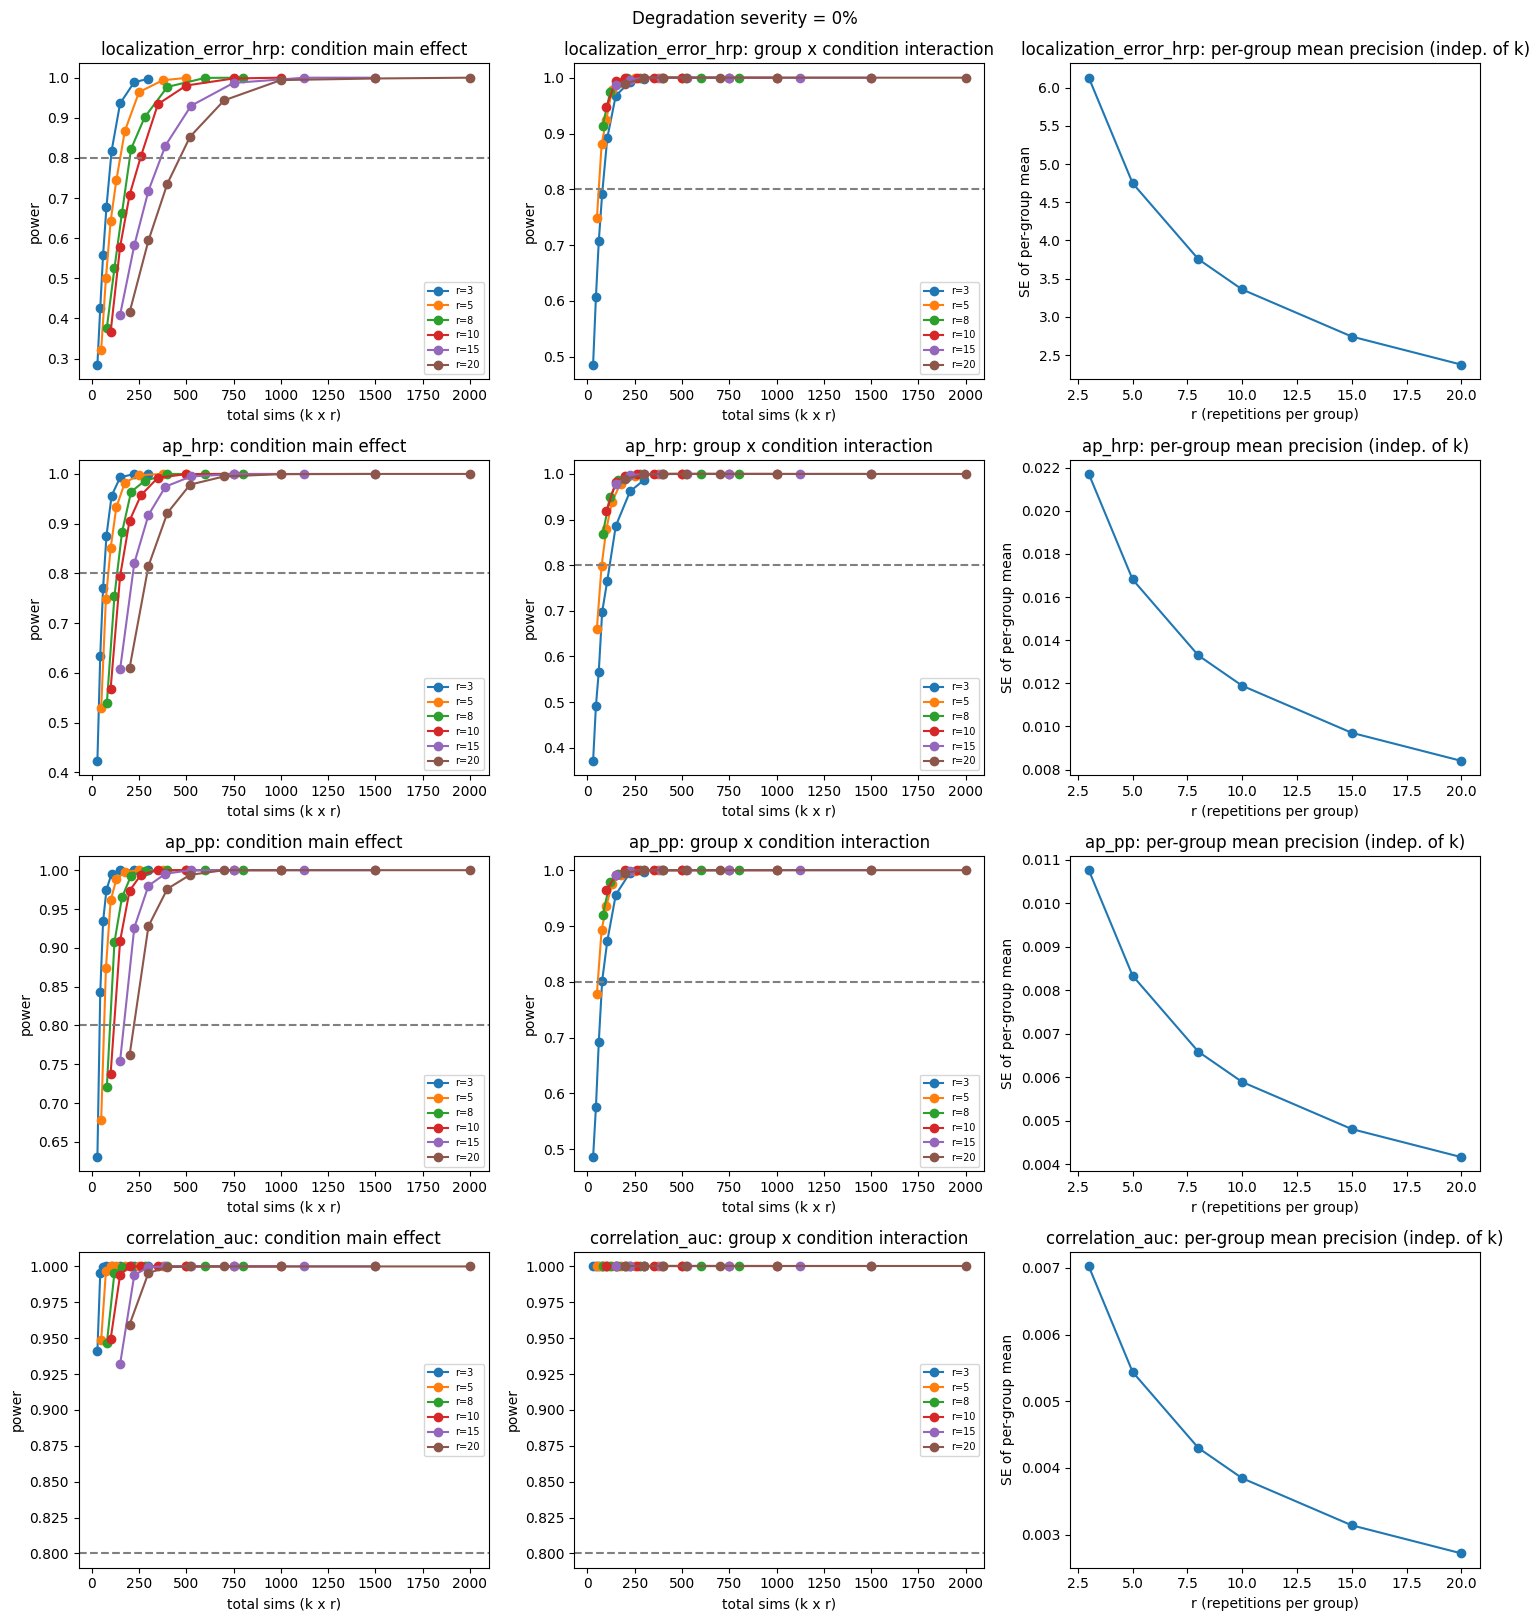

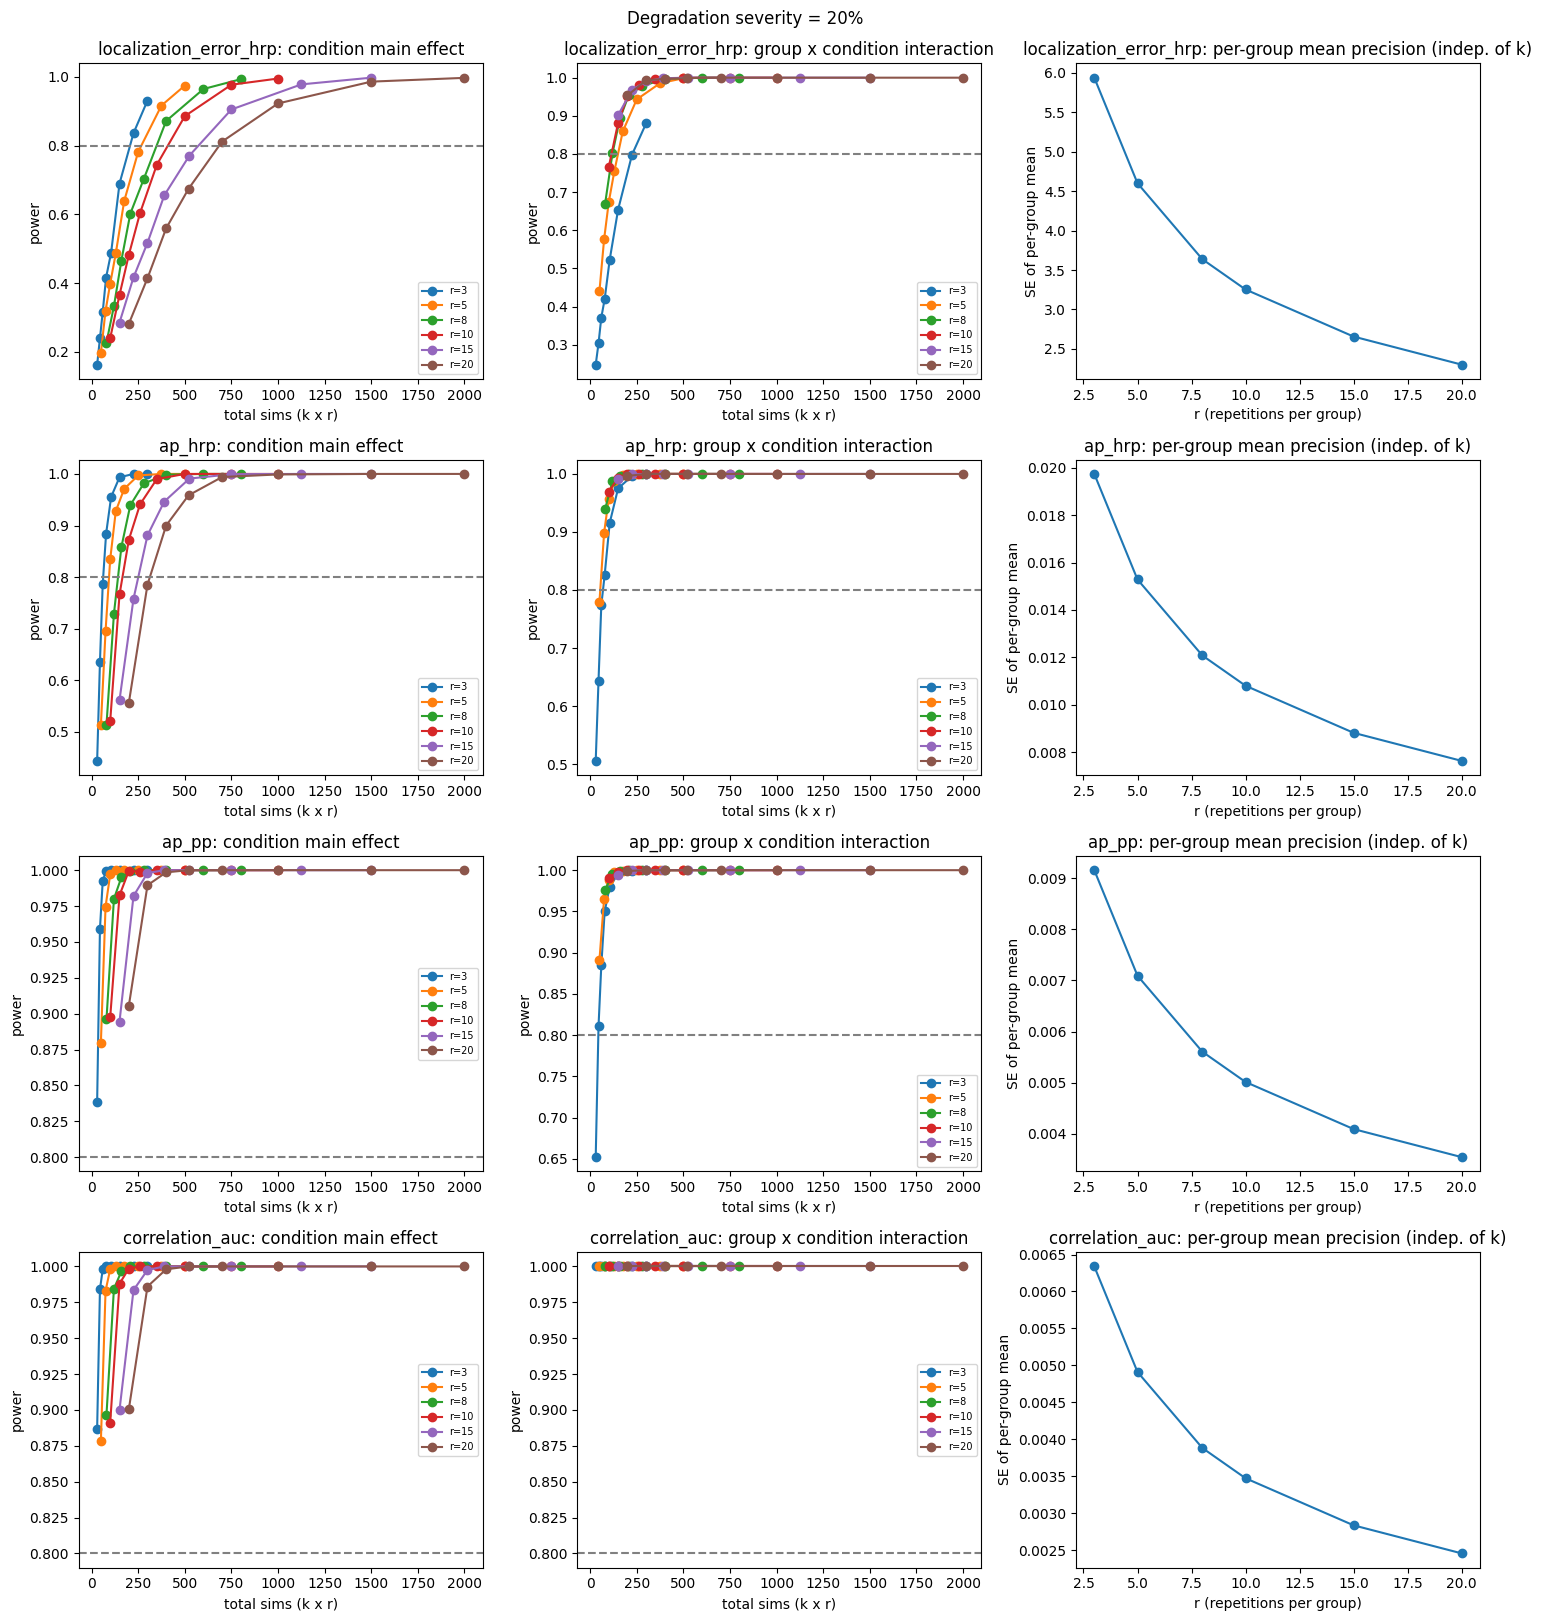

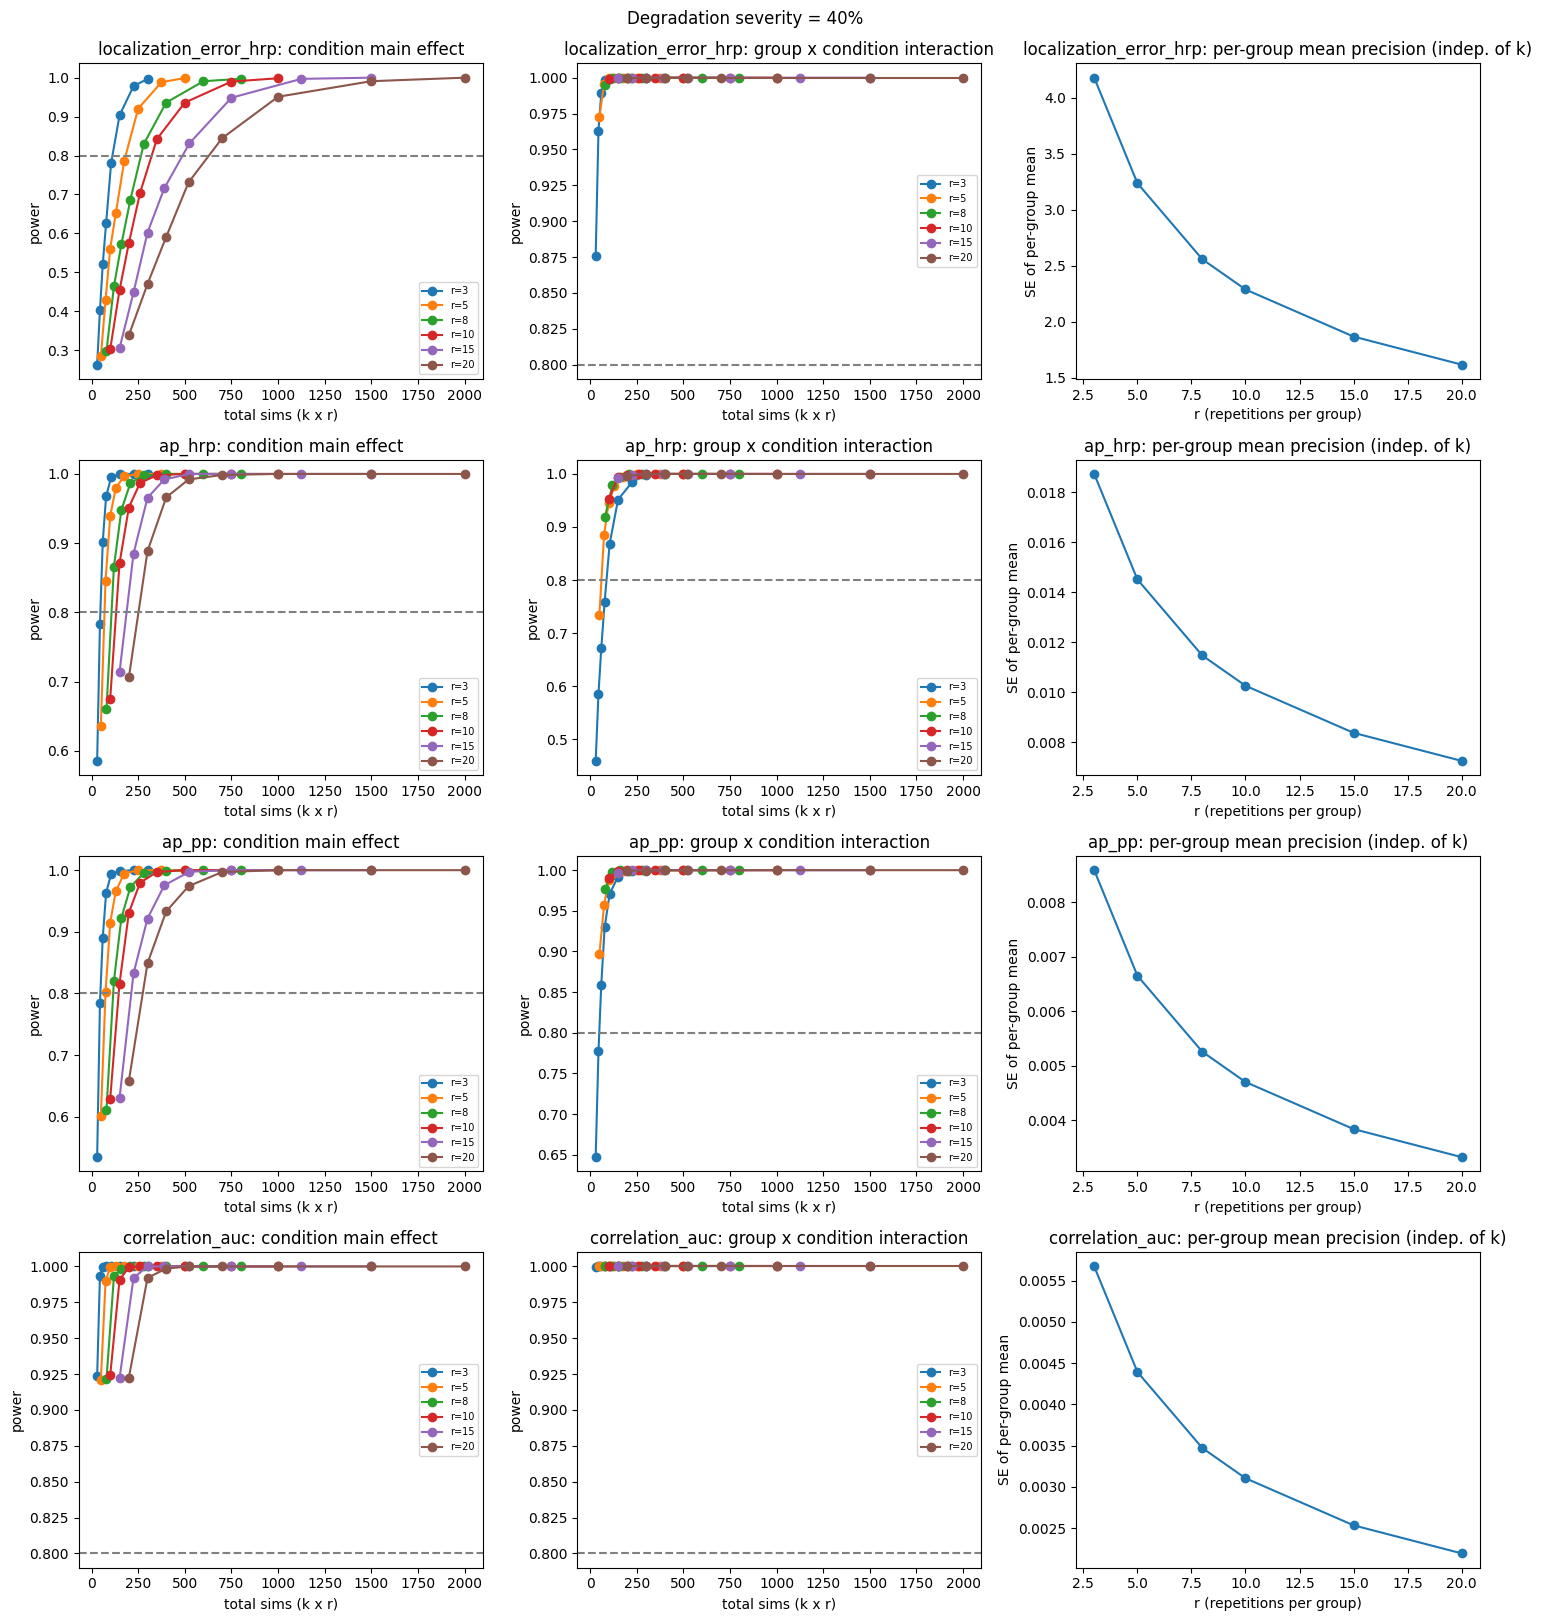

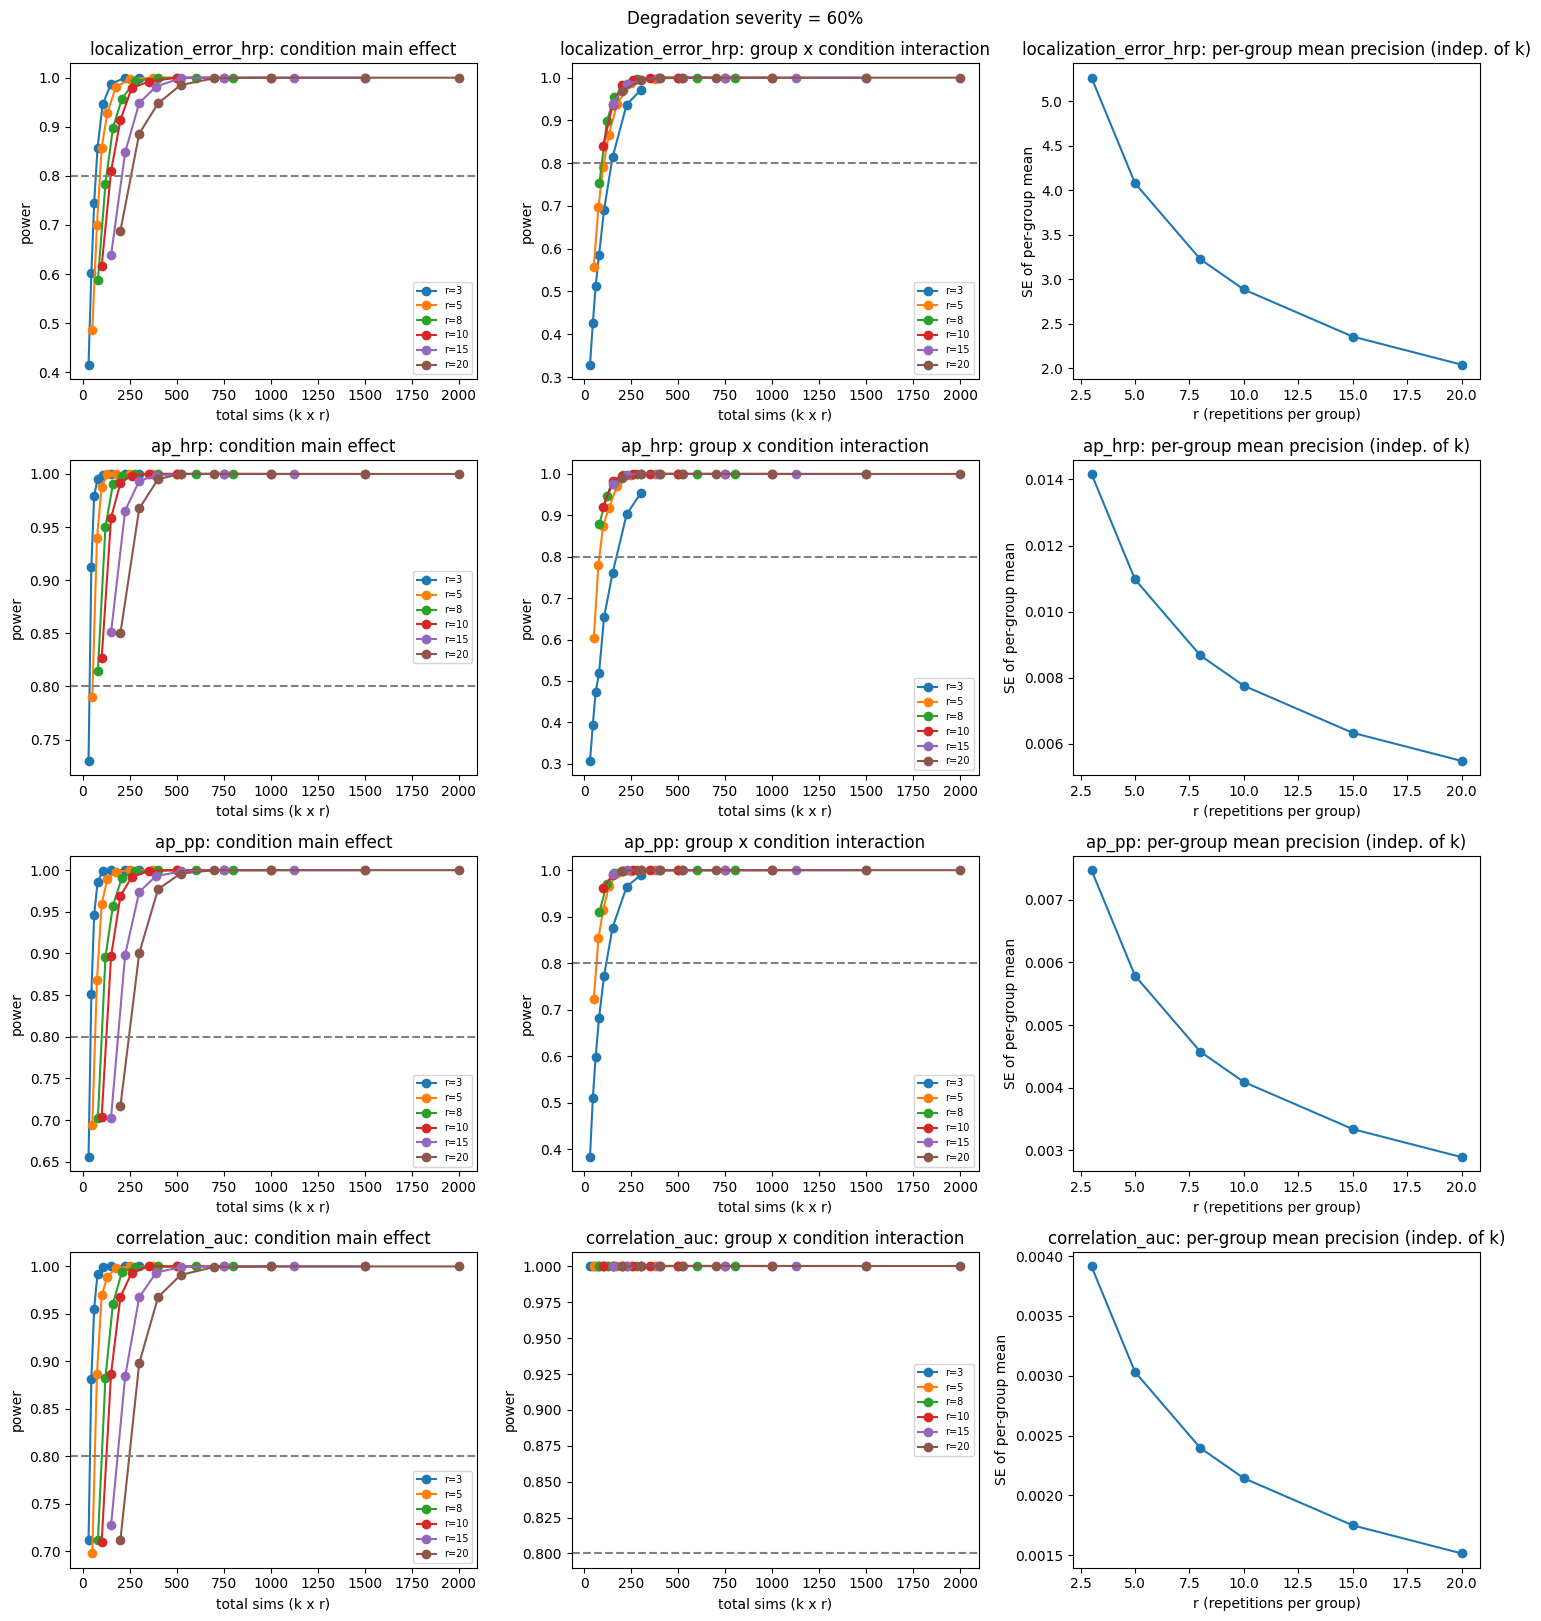

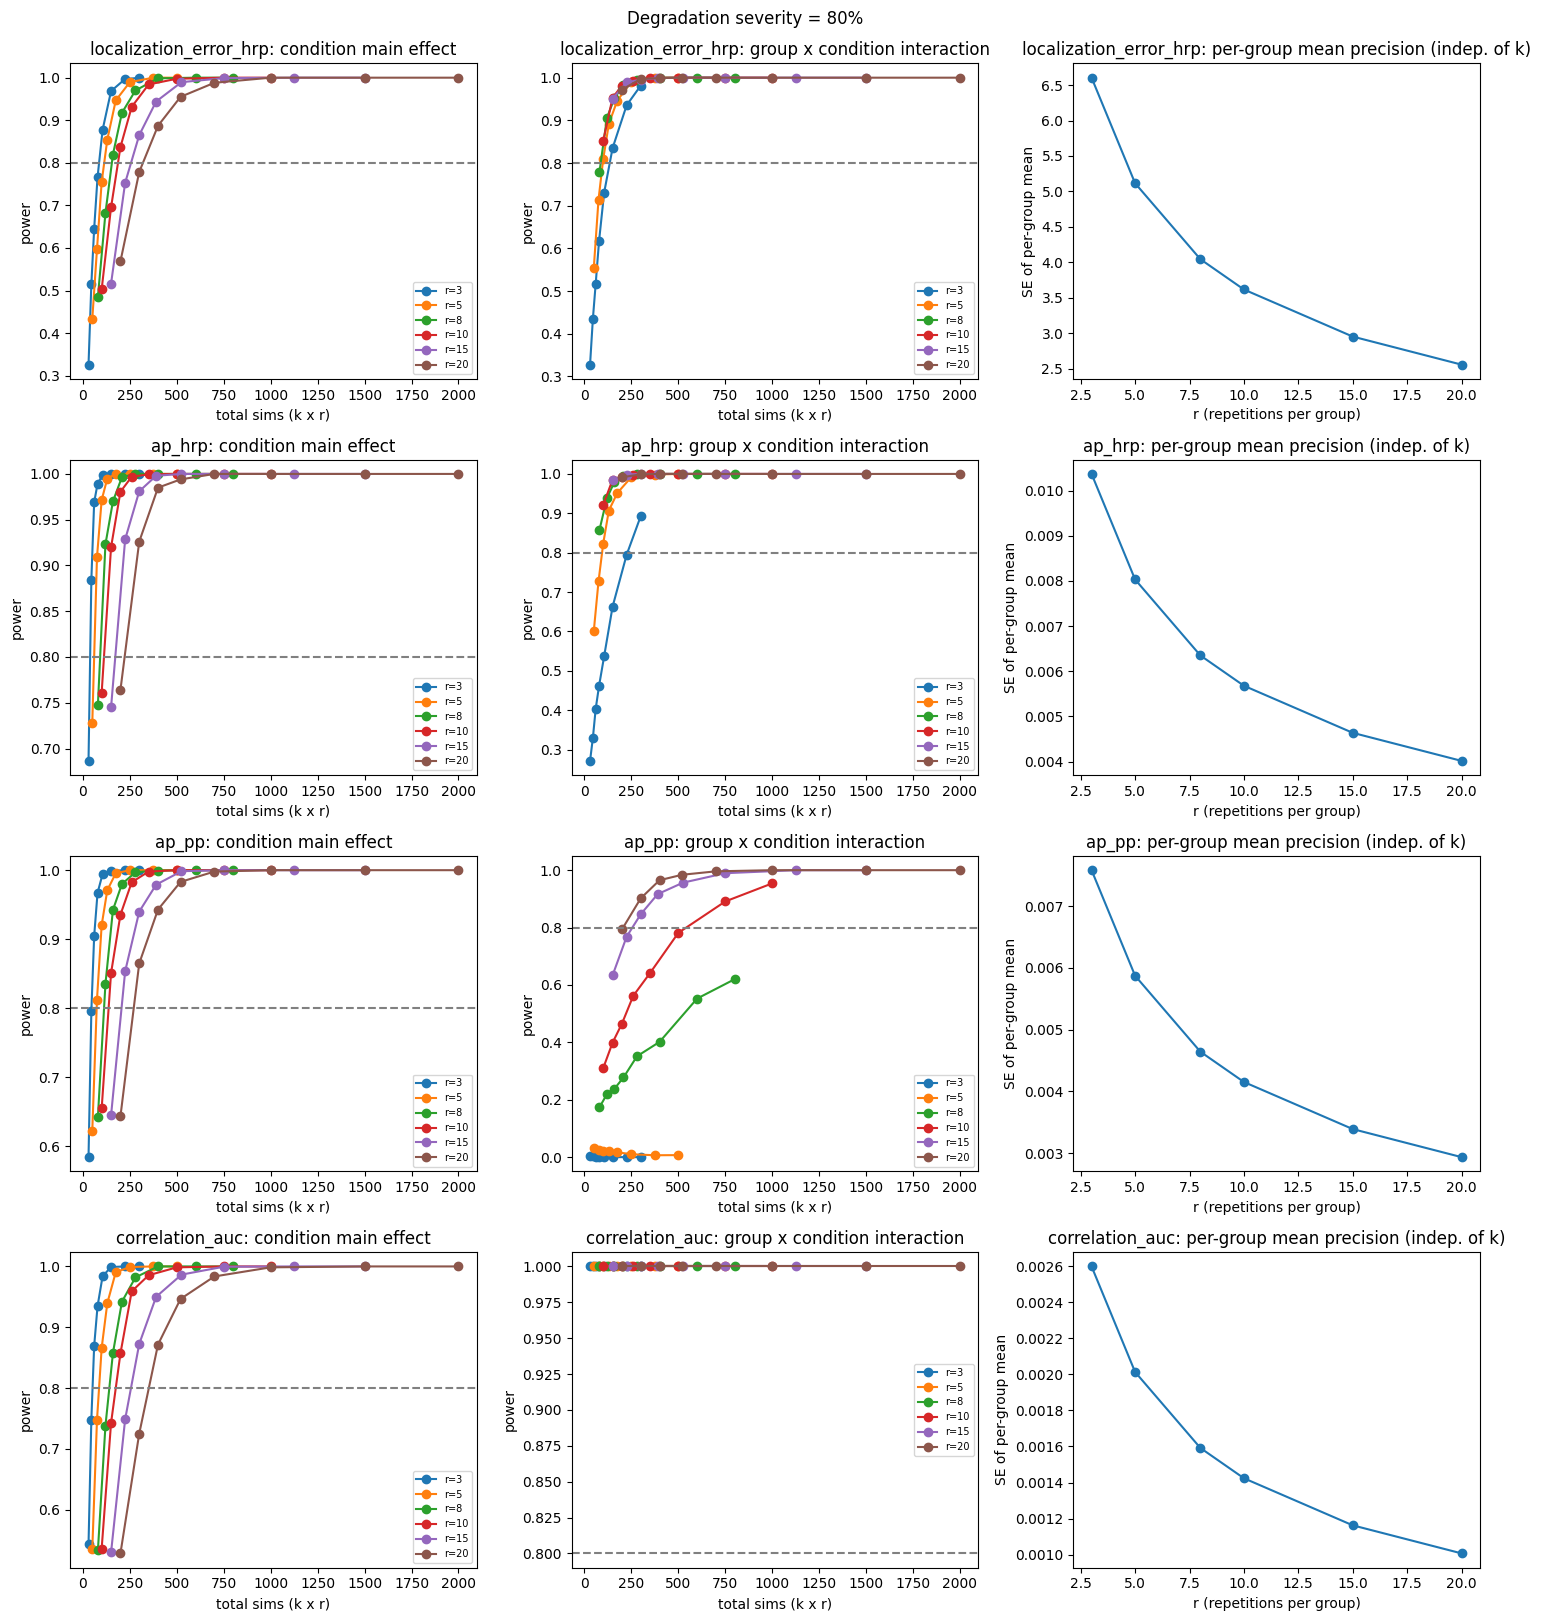

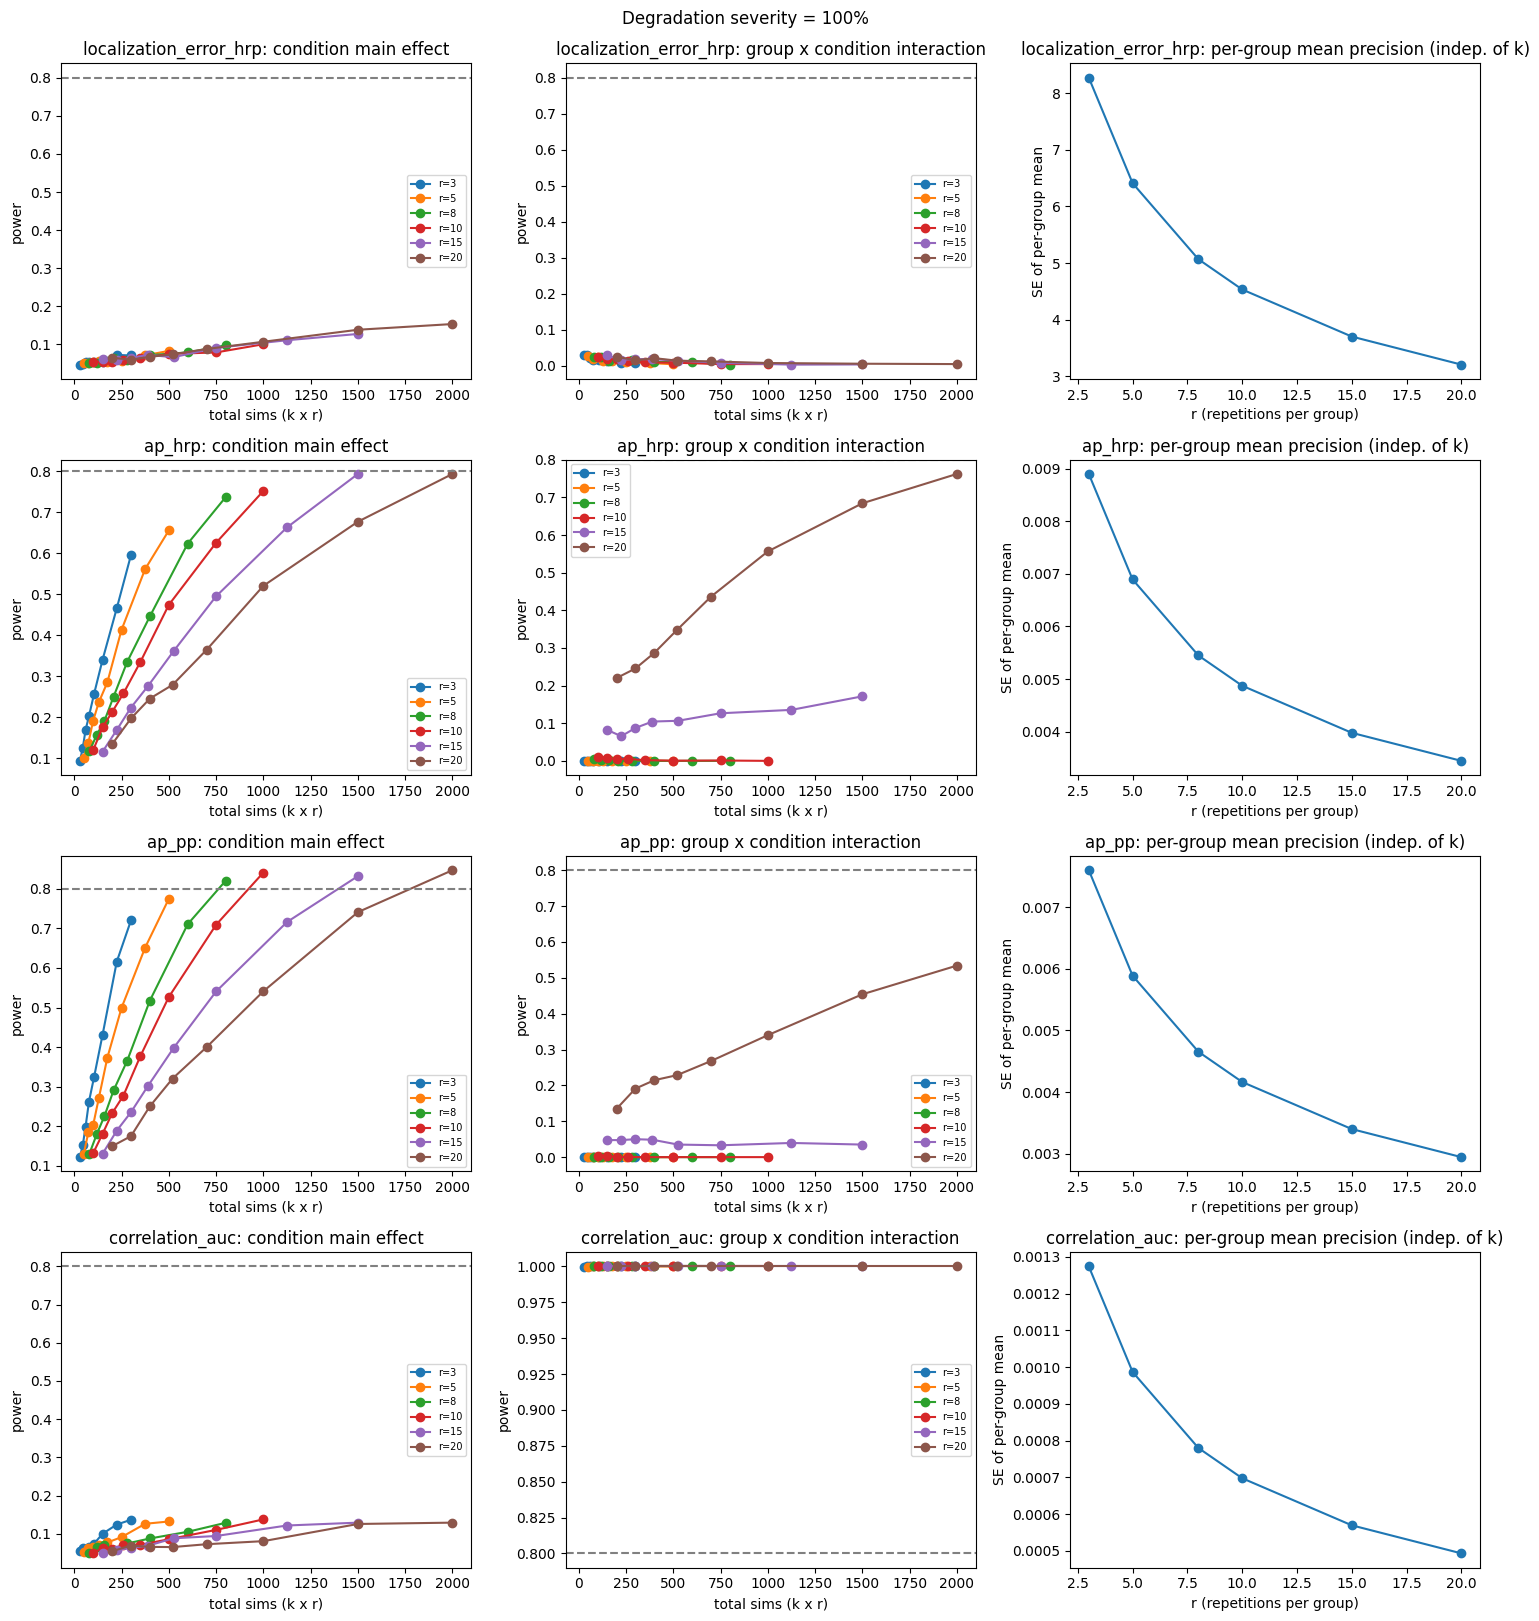

In [5]:
for pct in PERCENTAGES:
    fig = mm.viz.plot_power_precision_curves(power_results[pct], precision_results[pct], k_grid, r_grid, OUTCOMES)
    fig.suptitle(f"Degradation severity = {pct}%", y=1.01)
    fig.savefig(f"pilot_degradation_power_curves_pct{pct}.png", dpi=130)

## ✅ - Recommendation (region x repetition, given one connectome per severity)

Sized to the worst `(outcome, percentage, test)` combination across the whole grid --
same "size to the hardest case" principle as the other pilots. Combine with
`pilot_degradation_draws_power_analysis.ipynb`'s own draw-count recommendation by
taking the more conservative `(k, r)` / `c` of the two -- that's the real cost of the
independence assumption behind running these as two separate pilots instead of one
joint 3-way model.

In [6]:
def worst_case_power(power_results, test):
    worst = np.ones((len(k_grid), len(r_grid)))
    for pct in PERCENTAGES:
        for outcome in OUTCOMES:
            worst = np.minimum(worst, power_results[pct][outcome][test])
    return worst

worst_condition = worst_case_power(power_results, "condition")
worst_interaction = worst_case_power(power_results, "interaction")

THRESHOLD = 0.8
for name, worst in [("condition (main effect)", worst_condition), ("interaction (method x region)", worst_interaction)]:
    ok = worst >= THRESHOLD
    if not ok.any():
        print(f"{name}: no (k, r) in this grid reaches {THRESHOLD} power across every outcome/percentage -- extend the grid.")
        continue
    total_sims = np.array(k_grid)[:, None] * np.array(r_grid)[None, :]
    candidates = np.where(ok, total_sims, np.inf)
    i, j = np.unravel_index(np.argmin(candidates), candidates.shape)
    print(f"{name}: smallest design clearing {THRESHOLD} power everywhere -- "
          f"k={k_grid[i]} regions, r={r_grid[j]} repetitions "
          f"(worst-case power={worst[i, j]:.3f}, total sims/method={k_grid[i]*r_grid[j]}).")

condition (main effect): no (k, r) in this grid reaches 0.8 power across every outcome/percentage -- extend the grid.
interaction (method x region): no (k, r) in this grid reaches 0.8 power across every outcome/percentage -- extend the grid.
